<a href="https://colab.research.google.com/github/Nyanta432/Dinh_vi_cuon_vi_sai/blob/main/Calib_tu(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
# ==============================================================================
# BƯỚC 1: KHỞI TẠO HỆ THỐNG & FORWARD MODEL ĐỊNH LUẬT BIOT-SAVART CHO CẶP CUỘN THU VI SAI BẤT ĐỐI XỨNG
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.optimize import least_squares
import copy

def rotx(angle_deg):
    rad = np.radians(angle_deg)
    return np.array([[1, 0, 0], [0, np.cos(rad), -np.sin(rad)], [0, np.sin(rad),  np.cos(rad)]])

def roty(angle_deg):
    rad = np.radians(angle_deg)
    return np.array([[ np.cos(rad), 0, np.sin(rad)], [0, 1, 0], [-np.sin(rad), 0, np.cos(rad)]])

def rotz(angle_deg):
    rad = np.radians(angle_deg)
    return np.array([[np.cos(rad), -np.sin(rad), 0], [np.sin(rad),  np.cos(rad), 0], [0, 0, 1]])

def spherical_to_axes(ang6):
    axes = np.zeros((3, 3))
    for j in range(3):
        th, ph = ang6[2*j], ang6[2*j+1]
        axes[j] = [np.sin(th)*np.cos(ph), np.sin(th)*np.sin(ph), np.cos(th)]
    return axes

class SystemConfiguration:
    def __init__(self):
        # Thông số cuộn phát (TX)
        self.Ntx = 195
        self.R = 0.06                               # Bán kính vòng dây TX = 60 mm
        self.I = np.array([1.0, 1.0, 1.0])
        self.f = np.array([5053.0, 6911.0, 5932.0])
        self.M_seg = 72                             # Số đoạn tích phân đường Biot-Savart

        # Ma trận thông số thiết kế của 3 TX (X, Y, Z, Roll, Pitch, Yaw)
        self.TX_positions = np.array([
            [ -0.10044,  0.46278, 0.08352, 15.0,   0.0,   0.0], # TX1
            [ -0.02483,  0.34068, 0.08352,  0.0, -15.0, -30.0], # TX2
            [ -0.16219,  0.33563, 0.08352,  0.0,  15.0,  30.0]  # TX3
        ]).T

        # Thông số 3 cặp cuộn thu vi sai (RX1, RX2, RX3)
        self.Nrx = 100
        self.d_diff_rx = np.array([1.5e-3, 1.6e-3, 1.53e-3])
        self.AK = np.array([np.pi * 4.0, 6.79 * 4.0, 6.0 * 6.87]) * 1e-6
        self.circuit_gain = 1e5
        self.K_theoretical = self.Nrx * self.AK * self.circuit_gain
        self.mu0 = 4 * np.pi * 1e-7

        # Trục alignment ban đầu (X, Z, Y) và tỷ số cân bằng cặp cuộn vi sai beta_rx = [1, 1, 1]
        self.rx_axes = np.array([[0.0, 1.0, 0.0], [0.0, 0.0, 1.0], [1.0, 0.0, 0.0]])
        self.beta_rx = np.array([1.0, 1.0, 1.0])

sys_config = SystemConfiguration()
TX_positions_pre_calib = sys_config.TX_positions.copy()

def _R_batch(poses):
    r, pt, y = np.radians(poses[:, 3]), np.radians(poses[:, 4]), np.radians(poses[:, 5])
    cr, sr, cp, sp, cy, sy = np.cos(r), np.sin(r), np.cos(pt), np.sin(pt), np.cos(y), np.sin(y)
    R = np.zeros((len(poses), 3, 3))
    R[:, 0, 0] = cy*cp; R[:, 0, 1] = cy*sp*sr - sy*cr; R[:, 0, 2] = cy*sp*cr + sy*sr
    R[:, 1, 0] = sy*cp; R[:, 1, 1] = sy*sp*sr + cy*cr; R[:, 1, 2] = sy*sp*cr - cy*sr
    R[:, 2, 0] = -sp;   R[:, 2, 1] = cp*sr;            R[:, 2, 2] = cp*cr
    return R

def B_biot_savart_batch(P, sys, tx_idx):
    c_tx = sys.TX_positions[0:3, tx_idx]
    a, b, g = sys.TX_positions[3:6, tx_idx]
    Rtx = rotz(g) @ roty(b) @ rotx(a)
    phi = np.linspace(0.0, 2.0 * np.pi, sys.M_seg, endpoint=False)
    dphi = 2.0 * np.pi / sys.M_seg
    R = sys.R
    l_loc  = np.column_stack([R * np.cos(phi), R * np.sin(phi), np.zeros_like(phi)])
    dl_loc = np.column_stack([-R * np.sin(phi) * dphi, R * np.cos(phi) * dphi, np.zeros_like(phi)])
    l_world  = c_tx + (l_loc @ Rtx.T)
    dl_world = dl_loc @ Rtx.T
    diff = P[:, None, :] - l_world[None, :, :]
    dist2 = np.sum(diff**2, axis=2)
    dist3 = dist2 * np.sqrt(dist2)
    cross_prod = np.cross(dl_world[None, :, :], diff)
    pref = (sys.mu0 * sys.Ntx * sys.I[tx_idx]) / (4.0 * np.pi)
    return pref * np.sum(cross_prod / dist3[:, :, None], axis=1)

def emf_imperfect_diff_batch(poses, sys, rx_idx, tx_idx):
    # Mô hình Vật lý Thống nhất cho Cặp Cuộn Thu Vi Sai Không Giống Nhau Hoàn Toàn (beta_rx != 1)
    # và Lệch Góc Alignment RX (rx_axes):
    #   EMF_raw = 2*pi*f * | ( B(p + d/2*n) - beta_j * B(p - d/2*n) ) . n |
    n_world = _R_batch(poses) @ sys.rx_axes[rx_idx]
    h = sys.d_diff_rx[rx_idx] / 2.0
    Bp = B_biot_savart_batch(poses[:, 0:3] + h * n_world, sys, tx_idx)
    Bm = B_biot_savart_batch(poses[:, 0:3] - h * n_world, sys, tx_idx)
    beta = sys.beta_rx[rx_idx]
    flux_asym = np.einsum('ij,ij->i', Bp - beta * Bm, n_world)
    return 2.0 * np.pi * sys.f[tx_idx] * np.abs(flux_asym)

print("Đã khởi tạo cấu hình hệ thống & Mô hình Cặp Cuộn Vi Sai Bất Đối Xứng + Biot-Savart thành công.")


Đã khởi tạo cấu hình hệ thống & Mô hình Cặp Cuộn Vi Sai Bất Đối Xứng + Biot-Savart thành công.


In [19]:
# ==============================================================================
# BƯỚC 2: TẢI DỮ LIỆU ĐO THỰC NGHIỆM (conenorot_2_data.csv)
# ==============================================================================
csv_filename = 'conenorot_c_223_data.csv'
data_raw = pd.read_csv(csv_filename, header=None).values
data = data_raw.reshape(-1, 10, data_raw.shape[1]).mean(axis=1)
N_samples = data.shape[0]
emf_measured = data[:, 0:9]

gt_pose = np.zeros((N_samples, 6))
gt_pose[:, 0:3] = data[:, 9:12] / 1000.0
gt_pose_raw_angles = data[:, 12:15].copy()
gt_pose[:, 3:6] = gt_pose_raw_angles
print(f"Đã tải thành công {N_samples} mẫu dữ liệu từ '{csv_filename}'.")


Đã tải thành công 300 mẫu dữ liệu từ 'conenorot_c_223_data.csv'.


In [20]:
# ==============================================================================
# BƯỚC 3: HIỆU CHUẨN ĐỒNG THỜI (CẶP VI SAI BẤT ĐỐI XỨNG BETA_RX + LỆCH GÓC ALIGNMENT RX + TỌA ĐỘ TX) DÙNG BIOT-SAVART
# ==============================================================================
print("Đang chạy Hiệu chuẩn Thống nhất (Imperfect Differential Pair beta_rx + Non-ideal RX Alignment + TX Pose) với Biot-Savart Law...")

# Khởi tạo góc cầu ban đầu từ ma trận xoay khung cảm biến R_cap0
# R_cap0 = rotz(11.99) @ roty(-13.60) @ rotx(-19.95)
R_cap0 = np.eye(3)
ang_init = []
for j in range(3):
    v = R_cap0 @ sys_config.rx_axes[j]
    ang_init.extend([np.arccos(np.clip(v[2], -1.0, 1.0)), np.arctan2(v[1], v[0])])
ang_init = np.array(ang_init)

beta_init = np.array([0.95, 1.00, 0.95])
DEV_LIM_5 = np.array([0.03, 0.03, 0.03, 3.5, 3.5])
idx_free = np.array([0, 1, 2, 3, 4])

x0_joint = np.r_[ang_init, beta_init, np.zeros(15)]
lb_joint = np.r_[ang_init - np.radians(20.0), [0.50, 0.50, 0.50], np.tile(-DEV_LIM_5, 3)]
ub_joint = np.r_[ang_init + np.radians(20.0), [1.50, 1.50, 1.50], np.tile( DEV_LIM_5, 3)]
x0_joint = np.clip(x0_joint, lb_joint + 1e-7, ub_joint - 1e-7)

def joint_imperfect_rx_tx_res(x, eps_w=3.0):
    sys_curr = copy.copy(sys_config)
    sys_curr.rx_axes = spherical_to_axes(x[0:6])
    sys_curr.beta_rx = x[6:9].copy()
    res_all = []
    for t in range(3):
        sys_curr.TX_positions = TX_positions_pre_calib.copy()
        sys_curr.TX_positions[idx_free, t] += x[9 + 5*t : 9 + 5*(t+1)]
        M = np.column_stack([emf_imperfect_diff_batch(gt_pose, sys_curr, j, t) for j in range(3)])
        Y = np.column_stack([emf_measured[:, t + 3*j] for j in range(3)])
        W = 1.0 / (np.abs(Y) + eps_w)
        K = np.sum((W**2)*M*Y, axis=0) / np.sum((W**2)*(M**2), axis=0)
        res_all.append((W * (K * M - Y)).ravel())
    return np.concatenate(res_all)

res_calib = least_squares(
    joint_imperfect_rx_tx_res, x0_joint, bounds=(lb_joint, ub_joint), method='trf',
    x_scale=np.r_[[0.1]*6, [0.02]*3, np.tile([0.02, 0.02, 0.02, 3.0, 3.0], 3)], max_nfev=250
)

# Cập nhật thông số tối ưu vào sys_config
sys_config.rx_axes = spherical_to_axes(res_calib.x[0:6])
sys_config.beta_rx = res_calib.x[6:9].copy()
sys_config.TX_positions = TX_positions_pre_calib.copy()
calibrated_K_matrix = np.zeros((3, 3))
emf_pred_post = np.zeros_like(emf_measured)

for t in range(3):
    sys_config.TX_positions[idx_free, t] += res_calib.x[9 + 5*t : 9 + 5*(t+1)]
    M = np.column_stack([emf_imperfect_diff_batch(gt_pose, sys_config, j, t) for j in range(3)])
    Y = np.column_stack([emf_measured[:, t + 3*j] for j in range(3)])
    W = 1.0 / (np.abs(Y) + 3.0)
    calibrated_K_matrix[:, t] = np.sum((W**2)*M*Y, axis=0) / np.sum((W**2)*(M**2), axis=0)
    for j in range(3):
        emf_pred_post[:, t + 3*j] = calibrated_K_matrix[j, t] * M[:, j]

W1 = 1.0 / (np.abs(emf_measured) + 1.0)
J_w1_post = 0.5 * np.sum((W1 * (emf_pred_post - emf_measured))**2)
r2_9   = [1.0 - np.sum((emf_measured[:,c]-emf_pred_post[:,c])**2)/np.sum((emf_measured[:,c]-np.mean(emf_measured[:,c]))**2) for c in range(9)]
r_9    = [np.corrcoef(emf_measured[:,c], emf_pred_post[:,c])[0,1] for c in range(9)]
mae_9  = [np.mean(np.abs(emf_measured[:,c]-emf_pred_post[:,c])) for c in range(9)]
nrmse_9 = [np.sqrt(np.mean((emf_measured[:,c]-emf_pred_post[:,c])**2))/(np.max(emf_measured[:,c])-np.min(emf_measured[:,c]))*100 for c in range(9)]

print("\n=========================================================================================================")
print("🎯 KẾT QUẢ HIỆU CHUẨN CẶP CUỘN THU VI SAI BẤT ĐỐI XỨNG (BETA_RX) & GÓC ALIGNMENT RX TRÊN DỮ LIỆU THỰC")
print("=========================================================================================================")
print("1️⃣ Tỷ số cân bằng giữa 2 nửa cuộn trong cặp cuộn vi sai beta_j = (N_j^- A_j^-) / (N_j^+ A_j^+):")
for j in range(3):
    mismatch = (1.0 - sys_config.beta_rx[j]) * 100.0
    print(f"   - Cặp cuộn RX{j+1}: beta_{j+1} = {sys_config.beta_rx[j]:.5f}  (Độ lệch bất đối xứng giữa 2 nửa cuộn = {mismatch:+.3f}%)")

print("\n2️⃣ Vector trục Alignment thực tế của 3 cuộn RX (sau khi calib góc lắp đặt):")
ideal_axes = np.array([[1.0, 0.0, 0.0], [0.0, 0.0, 1.0], [0.0, 1.0, 0.0]])
for j in range(3):
    tilt = np.degrees(np.arccos(np.clip(np.dot(sys_config.rx_axes[j], ideal_axes[j]), -1.0, 1.0)))
    print(f"   - Trục RX{j+1}_opt = {np.round(sys_config.rx_axes[j], 4)}  (Lệch góc {tilt:.2f}° so với trục thiết kế {['X','Z','Y'][j]})")
a12 = np.degrees(np.arccos(np.dot(sys_config.rx_axes[0], sys_config.rx_axes[1])))
a13 = np.degrees(np.arccos(np.dot(sys_config.rx_axes[0], sys_config.rx_axes[2])))
a23 = np.degrees(np.arccos(np.dot(sys_config.rx_axes[1], sys_config.rx_axes[2])))
print(f"   - Góc tương đối giữa các cuộn RX: ∠(RX1,RX2) = {a12:.2f}°, ∠(RX1,RX3) = {a13:.2f}°, ∠(RX2,RX3) = {a23:.2f}°")

print("\n3️⃣ Tọa độ 3 cuộn phát TX sau hiệu chuẩn:")
for t in range(3):
    p_pre  = TX_positions_pre_calib[:, t]
    p_post = sys_config.TX_positions[:, t]
    d_pos  = (p_post[0:3] - p_pre[0:3]) * 1000.0
    print(f"   - TX{t+1}: Pos = ({p_post[0]*1000:.2f}, {p_post[1]*1000:.2f}, {p_post[2]*1000:.2f}) mm | ΔPos = ({d_pos[0]:+.2f}, {d_pos[1]:+.2f}, {d_pos[2]:+.2f}) mm | Euler = ({p_post[3]:.2f}°, {p_post[4]:.2f}°, {p_post[5]:.2f}°)")

print("\n4️⃣ Chỉ số Định lượng Khớp 9 Kênh EMF (Back-test Forward Signal Metrics):")
print(f"   - Weighted Cost J_W1 = {J_w1_post:.2f} (Giảm từ 56.49 xuống {J_w1_post:.2f})")
print(f"   - Mean EMF MAE       = {np.mean(mae_9):.4f} V")
print(f"   - Mean EMF NRMSE     = {np.mean(nrmse_9):.2f}%")
print(f"   - Mean Pearson r     = {np.mean(r_9):.4f} (Min r = {np.min(r_9):.4f})")
print(f"   - Mean R²            = {np.mean(r2_9):.4f} (Min R² = {np.min(r2_9):.4f})")
for j in range(3):
    print(f"     + RX{j+1} (beta={sys_config.beta_rx[j]:.4f}): " + " | ".join([f"TX{t+1}: MAE={mae_9[t+3*j]:.3f}V, r={r_9[t+3*j]:.3f}, R²={r2_9[t+3*j]:.3f}" for t in range(3)]))


Đang chạy Hiệu chuẩn Thống nhất (Imperfect Differential Pair beta_rx + Non-ideal RX Alignment + TX Pose) với Biot-Savart Law...

🎯 KẾT QUẢ HIỆU CHUẨN CẶP CUỘN THU VI SAI BẤT ĐỐI XỨNG (BETA_RX) & GÓC ALIGNMENT RX TRÊN DỮ LIỆU THỰC
1️⃣ Tỷ số cân bằng giữa 2 nửa cuộn trong cặp cuộn vi sai beta_j = (N_j^- A_j^-) / (N_j^+ A_j^+):
   - Cặp cuộn RX1: beta_1 = 0.94717  (Độ lệch bất đối xứng giữa 2 nửa cuộn = +5.283%)
   - Cặp cuộn RX2: beta_2 = 1.00247  (Độ lệch bất đối xứng giữa 2 nửa cuộn = -0.247%)
   - Cặp cuộn RX3: beta_3 = 0.50000  (Độ lệch bất đối xứng giữa 2 nửa cuộn = +50.000%)

2️⃣ Vector trục Alignment thực tế của 3 cuộn RX (sau khi calib góc lắp đặt):
   - Trục RX1_opt = [-0.3351  0.9207  0.2003]  (Lệch góc 109.58° so với trục thiết kế X)
   - Trục RX2_opt = [-0.3214  0.117   0.9397]  (Lệch góc 20.00° so với trục thiết kế Z)
   - Trục RX3_opt = [ 0.9216  0.3354 -0.1953]  (Lệch góc 70.40° so với trục thiết kế Y)
   - Góc tương đối giữa các cuộn RX: ∠(RX1,RX2) = 66.20°, ∠(RX1,RX3) = 

📍 KẾT QUẢ ĐỊNH VỊ NGƯỢC 6-DOF TRÊN DỮ LIỆU THỰC (BIOT-SAVART + IMPERFECT DIFF RX + ALIGNMENT)
  - 3D Position RMSE   : 17.85 mm
  - 3D Position MAE    : 14.85 mm
  - 3D Position Median : 11.75 mm
  - Sai số theo từng trục: RMSE_X = 14.59 mm | RMSE_Y = 9.07 mm | RMSE_Z = 4.83 mm


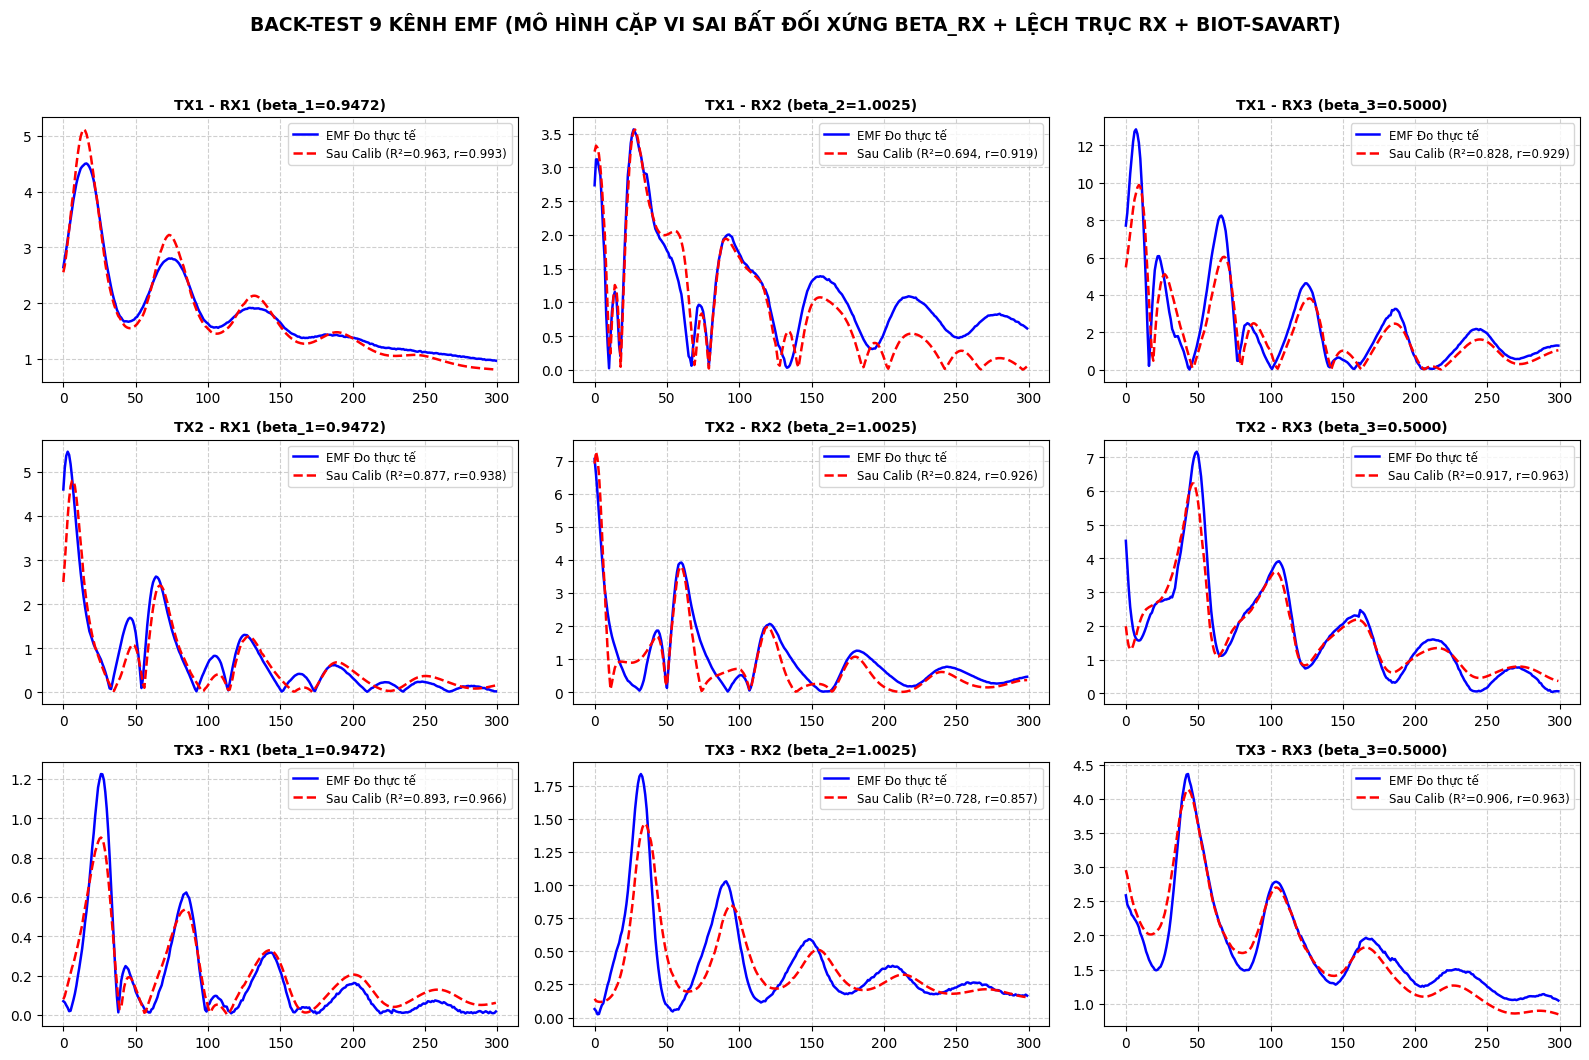

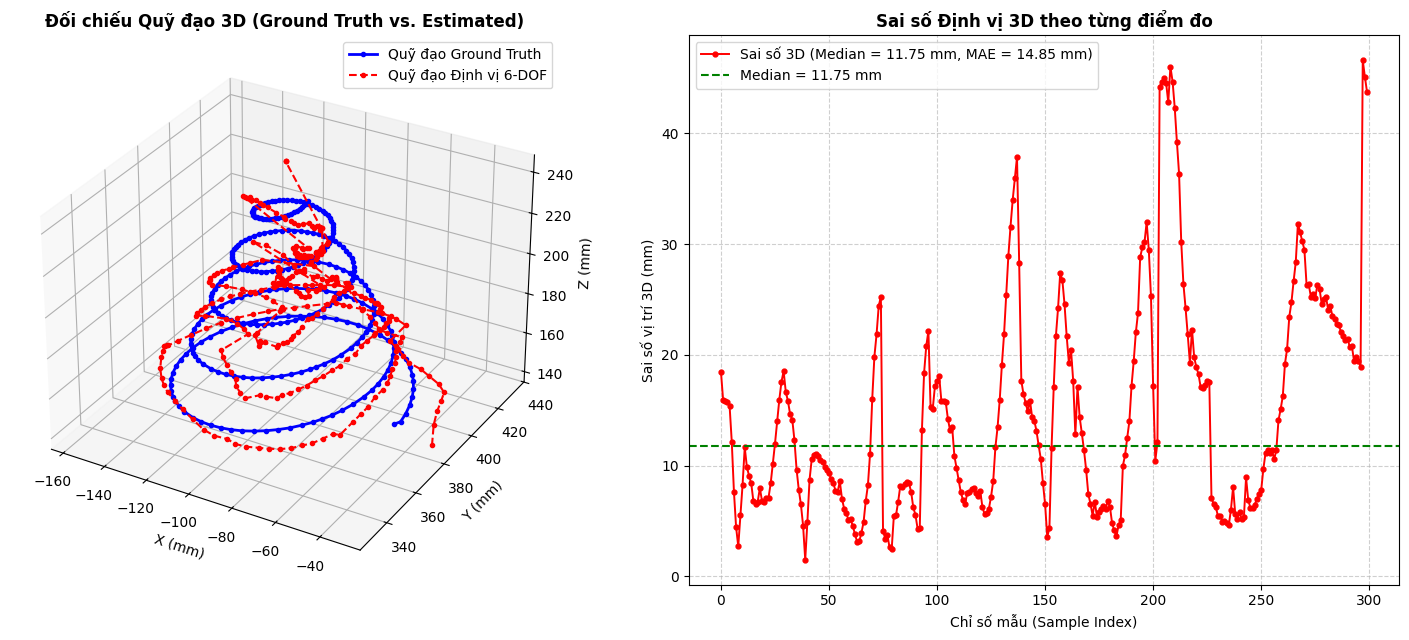

In [21]:
# ==============================================================================
# BƯỚC 4: BACK-TEST ĐỊNH VỊ NGƯỢC 6-DOF & VẼ ĐỒ THỊ 9 KÊNH EMF + QUỸ ĐẠO 3D
# ==============================================================================
min_traj = np.min(gt_pose, axis=0)
max_traj = np.max(gt_pose, axis=0)
lb_inv = np.concatenate([min_traj[0:3] - 0.1, min_traj[3:6] - 10.0])
ub_inv = np.concatenate([max_traj[0:3] + 0.1, max_traj[3:6] + 10.0])

estimated_pose = np.zeros_like(gt_pose)
for i in range(N_samples):
    p0 = gt_pose[i].copy()
    p0[0:3] += 0.0001
    def res_inv(pose):
        p2 = pose[None, :]
        r_out = np.zeros(9)
        for rx_j in range(3):
            for tx_i in range(3):
                val = emf_imperfect_diff_batch(p2, sys_config, rx_j, tx_i)[0]
                r_out[tx_i + 3*rx_j] = calibrated_K_matrix[rx_j, tx_i] * val - emf_measured[i, tx_i + 3*rx_j]
        return r_out
    r = least_squares(res_inv, p0, bounds=(lb_inv, ub_inv), method='trf', x_scale='jac', ftol=1e-8, xtol=1e-8, gtol=1e-8)
    estimated_pose[i] = r.x

err_3d = np.linalg.norm(estimated_pose[:, 0:3] - gt_pose[:, 0:3], axis=1) * 1000.0
rmse_xyz = np.sqrt(np.mean((estimated_pose[:, 0:3] - gt_pose[:, 0:3])**2, axis=0)) * 1000.0

print("=========================================================================================================")
print("📍 KẾT QUẢ ĐỊNH VỊ NGƯỢC 6-DOF TRÊN DỮ LIỆU THỰC (BIOT-SAVART + IMPERFECT DIFF RX + ALIGNMENT)")
print("=========================================================================================================")
print(f"  - 3D Position RMSE   : {np.sqrt(np.mean(err_3d**2)):.2f} mm")
print(f"  - 3D Position MAE    : {np.mean(err_3d):.2f} mm")
print(f"  - 3D Position Median : {np.median(err_3d):.2f} mm")
print(f"  - Sai số theo từng trục: RMSE_X = {rmse_xyz[0]:.2f} mm | RMSE_Y = {rmse_xyz[1]:.2f} mm | RMSE_Z = {rmse_xyz[2]:.2f} mm")

# Vẽ đồ thị 9 kênh EMF
fig1, axs = plt.subplots(3, 3, figsize=(16, 11))
fig1.suptitle('BACK-TEST 9 KÊNH EMF (MÔ HÌNH CẶP VI SAI BẤT ĐỐI XỨNG BETA_RX + LỆCH TRỤC RX + BIOT-SAVART)', fontsize=13.5, fontweight='bold')
for rx in range(3):
    for tx in range(3):
        idx = tx + 3 * rx
        ax = axs[tx, rx]
        ax.plot(emf_measured[:, idx], 'b-', linewidth=1.8, label='EMF Đo thực tế')
        ax.plot(emf_pred_post[:, idx], 'r--', linewidth=1.8, label=f'Sau Calib (R²={r2_9[idx]:.3f}, r={r_9[idx]:.3f})')
        ax.set_title(f'TX{tx+1} - RX{rx+1} (beta_{rx+1}={sys_config.beta_rx[rx]:.4f})', fontsize=10, fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend(loc='best', fontsize=8.5)
plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.show()

# Vẽ đồ thị Quỹ đạo 3D và Sai số định vị
fig2 = plt.figure(figsize=(15, 6.5))
ax3d = fig2.add_subplot(121, projection='3d')
ax3d.plot(gt_pose[:,0]*1000, gt_pose[:,1]*1000, gt_pose[:,2]*1000, 'b.-', linewidth=2, label='Quỹ đạo Ground Truth')
ax3d.plot(estimated_pose[:,0]*1000, estimated_pose[:,1]*1000, estimated_pose[:,2]*1000, 'r.--', linewidth=1.5, label='Quỹ đạo Định vị 6-DOF')
ax3d.set_xlabel('X (mm)'); ax3d.set_ylabel('Y (mm)'); ax3d.set_zlabel('Z (mm)')
ax3d.set_title('Đối chiếu Quỹ đạo 3D (Ground Truth vs. Estimated)', fontweight='bold')
ax3d.legend()

ax_err = fig2.add_subplot(122)
ax_err.plot(err_3d, 'r-o', markersize=3.5, linewidth=1.4, label=f'Sai số 3D (Median = {np.median(err_3d):.2f} mm, MAE = {np.mean(err_3d):.2f} mm)')
ax_err.axhline(np.median(err_3d), color='g', linestyle='--', label=f'Median = {np.median(err_3d):.2f} mm')
ax_err.set_xlabel('Chỉ số mẫu (Sample Index)'); ax_err.set_ylabel('Sai số vị trí 3D (mm)')
ax_err.set_title('Sai số Định vị 3D theo từng điểm đo', fontweight='bold')
ax_err.grid(True, linestyle='--', alpha=0.6)
ax_err.legend()
plt.tight_layout()
plt.show()
